<a href="https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_3_5_3_6_KMeans_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_3_5_3_6_KMeans_SVM.ipynb)

# MAT 422 - Sections 3.5 and 3.6: K-means and Support Vector Machines

**Topics:** K-means, Support vector machine

> Student note: This Colab badge is required for submission. Create or edit the notebook in Google Colab, then save it directly to GitHub so the badge/icon remains available for grading and reruns.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_classification
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

np.set_printoptions(precision=4, suppress=True)


## K-means

K-means clustering sorts unlabelled points into k groups. To see how good a grouping is, a method is, for each group we calculate the center, then calculate the total squared distance between each point and its group's center.

Lloyds algorithm does this:
1: randomly pick k points to be centers
2: group points by which center is closest
3: calculate new center by average of points
4: repeat 2 and 3 until group doesnt change.

The result changes based step 1 randomness, so scikit-learn tries several starts and keeps the rest.

We run this on 3 blobs:

Cluster centers:
[[-5.1989 -2.6887]
 [ 9.299   1.2333]
 [-6.5576  4.8014]]
Inertia: 202.2067992492687


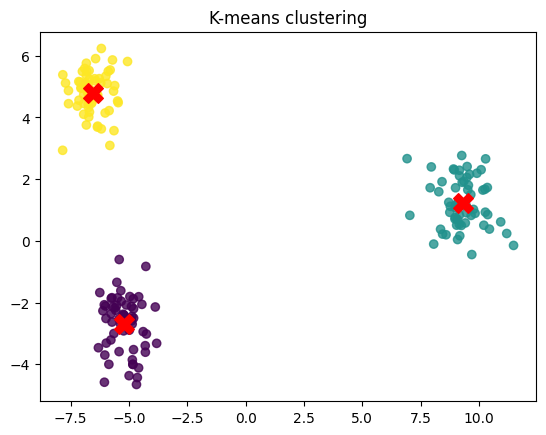

In [7]:
X, true_labels = make_blobs(n_samples=180, centers=3, cluster_std=0.7, random_state=422)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=422)
cluster_labels = kmeans.fit_predict(X)

print("Cluster centers:")
print(kmeans.cluster_centers_)
print("Inertia:", kmeans.inertia_)

plt.scatter(X[:,0], X[:,1], c=cluster_labels, cmap="viridis", alpha=0.8)
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], marker="X", s=200, color="red")
plt.title("K-means clustering")
plt.show()


The three x's are in the center of each blob. The inertia (sum of squared distances) is 202.2, so the squared distance from each point to its center is 202.2/180=1.12. A blob with standard deviation 0.7 in each of two coordinates should have an average squared distance of 2*0.7^2=0.98, so 1.12 is close enough.

We can write Lloyd's algorithm by hand:

starting centers:
 [[-5.3473 -1.6142]
 [-5.8161  3.0915]
 [-7.0344  4.9545]]
step 0: J =  13606.26
step 1: J =   6945.78
step 2: J =   3027.82
step 3: J =   1170.46
step 4: J =    211.51
step 5: J =    202.21
our centers:
 [[-5.1989 -2.6887]
 [ 9.299   1.2333]
 [-6.5576  4.8014]]
our J = 202.2068, scikit-learn inertia = 202.2068


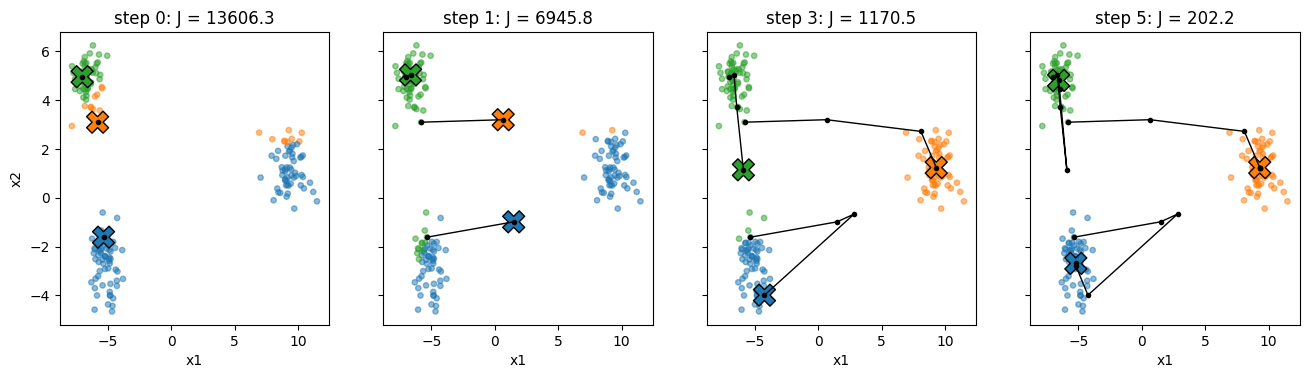

In [4]:
def assign(X, centers):
    d2 = ((X[:, None, :] - centers[None, :, :])**2).sum(axis=2)
    return d2.argmin(axis=1)

def objective(X, labels, centers):
    return ((X - centers[labels])**2).sum()

def lloyd(X, centers, max_iter=50):
    history, objs = [centers.copy()], []
    for _ in range(max_iter):
        labels = assign(X, centers)
        objs.append(objective(X, labels, centers))
        new_centers = np.array([X[labels == j].mean(axis=0) for j in range(len(centers))])
        if np.allclose(new_centers, centers):
            break
        centers = new_centers
        history.append(centers.copy())
    return centers, labels, history, objs

rng = np.random.default_rng(159)
start = X[rng.choice(len(X), 3, replace=False)]  # 3 random data points
print("starting centers:\n", start)
centers, labels, history, objs = lloyd(X, start)
for t, J in enumerate(objs):
    print(f"step {t}: J = {J:9.2f}")
print("our centers:\n", centers)
print(f"our J = {objs[-1]:.4f}, scikit-learn inertia = {kmeans.inertia_:.4f}")

colors = np.array(["tab:blue", "tab:orange", "tab:green"])
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True, sharey=True)
for a, t in zip(ax, [0, 1, 3, len(history) - 1]):
    a.scatter(X[:, 0], X[:, 1], c=colors[assign(X, history[t])], s=15, alpha=0.5)
    path = np.array(history[:t + 1])
    for j in range(3):
        a.plot(path[:, j, 0], path[:, j, 1], "k.-", lw=1)
    a.scatter(history[t][:, 0], history[t][:, 1], c=colors, marker="X", s=250, edgecolor="black")
    a.set(title=f"step {t}: J = {objs[t]:.1f}", xlabel="x1")
ax[0].set_ylabel("x2")
plt.show()

We see that two centers (Green, Orange)start in the top left and one (Blue) starts in the bottom left. Green takes most of the points in the top left and Blue takes points in the bottom left and right, while orange takes a few poins.

In step 1, Blue goes to the middle of the two clusters it takes, which leaves the bottom left cluster open for Green to move in. Orange goes between top left and right. Then, Orange goes to right, which makes Blue's group only bottom left, which makes Blue go to bottom left which makes Green go back to top left.

The final clusters and J (202.2) are close to what scikit-learn found, so this works. We also see that centers move around a lot, so it can take a while for things to settle down.

## Support vector machine

Every point has a label, y=-1 or y=1. A linear classifier computes the score of a point (f(x)=w^Tx+b) and predicts the sign of the score. We can define a "decision boundary" as the line where f(x)=0.

The "margin" is the sum of the distance between the line and the closest y=1 point, and the dist between the line and the y=-1 point. The SVM tries to widen this margin.

However, sometimes a line cant perfectly split the y=1 and y=-1, so a "soft margin" is used instead. It basically allows margins wider than the closest two points, and tries to make it so as many points on either side of the margin is correct.

Points inside the margin or are wrongly classified are called "support vectors".

Training accuracy: 0.9571428571428572
Number of support vectors: [13 13]


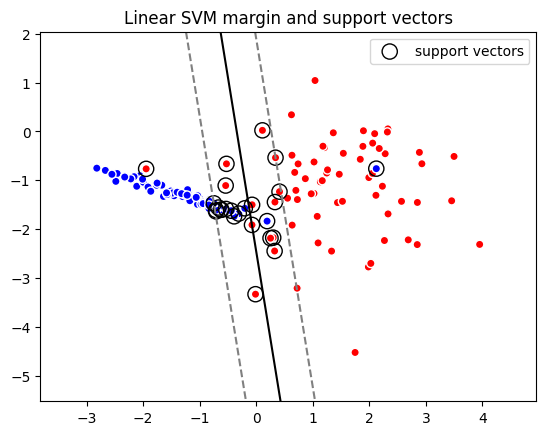

In [5]:
Xc, yc = make_classification(n_samples=140, n_features=2, n_redundant=0, n_informative=2,
                             n_clusters_per_class=1, class_sep=1.3, random_state=422)
svm = SVC(kernel="linear", C=1.0)
svm.fit(Xc, yc)
pred = svm.predict(Xc)

print("Training accuracy:", accuracy_score(yc, pred))
print("Number of support vectors:", svm.n_support_)

xx, yy = np.meshgrid(np.linspace(Xc[:,0].min()-1, Xc[:,0].max()+1, 150),
                     np.linspace(Xc[:,1].min()-1, Xc[:,1].max()+1, 150))
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["gray", "black", "gray"], linestyles=["--", "-", "--"])
plt.scatter(Xc[:,0], Xc[:,1], c=yc, cmap="bwr", edgecolor="white")
plt.scatter(svm.support_vectors_[:,0], svm.support_vectors_[:,1], s=120, facecolors="none", edgecolors="black", label="support vectors")
plt.title("Linear SVM margin and support vectors")
plt.legend()
plt.show()


The above example was using a soft margin, because no line can perfectly split the two. The below example uses a hard margin:

w = [0.6667 0.6667]  b = -3.0
margin width 2/||w|| = 2.1213   (by hand: 3/sqrt(2) = 2.1213)
  x1  x2   y   y*f(x)
   1   1  -1    1.667
   2   1  -1    1.000
   1   2  -1    1.000
   3   3   1    1.000
   4   3   1    1.667
   3   4   1    1.667
support vectors: [[2.0, 1.0], [1.0, 2.0], [3.0, 3.0]]
alpha_i * y_i = [-0.2222 -0.2222  0.4444]   sum = 0.0
w rebuilt as sum of alpha_i y_i x_i: [0.6667 0.6667]


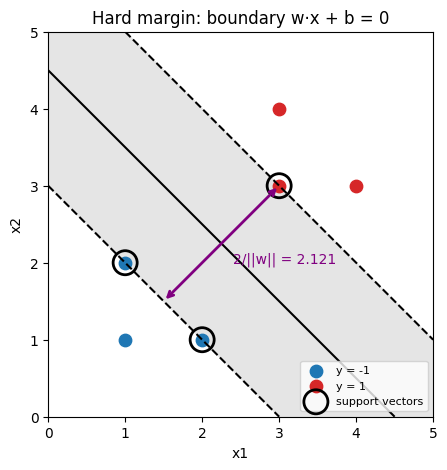

In [6]:
X_small = np.array([[1, 1], [2, 1], [1, 2], [3, 3], [4, 3], [3, 4]], dtype=float)
y_small = np.array([-1, -1, -1, 1, 1, 1])
hard = SVC(kernel="linear", C=1e6, tol=1e-9).fit(X_small, y_small)  # huge C = hard margin
w, b = hard.coef_[0], hard.intercept_[0]
width = 2 / np.linalg.norm(w)
f = X_small @ w + b

print("w =", w, " b =", round(b, 4))
print(f"margin width 2/||w|| = {width:.4f}   (by hand: 3/sqrt(2) = {3/np.sqrt(2):.4f})")
print("  x1  x2   y   y*f(x)")
for xi, yi, fi in zip(X_small, y_small, f):
    print(f"{xi[0]:4.0f}{xi[1]:4.0f}{yi:4d}   {yi*fi:6.3f}")
alpha_y = hard.dual_coef_[0]  # alpha_i * y_i, one number per support vector
print("support vectors:", hard.support_vectors_.tolist())
print("alpha_i * y_i =", alpha_y, "  sum =", round(alpha_y.sum(), 6))
print("w rebuilt as sum of alpha_i y_i x_i:", alpha_y @ hard.support_vectors_)

gx, gy = np.meshgrid(np.linspace(0, 5, 200), np.linspace(0, 5, 200))
G = hard.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
plt.figure(figsize=(5.5, 5))
plt.contourf(gx, gy, G, levels=[-1, 1], colors=["gray"], alpha=0.2)
plt.contour(gx, gy, G, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
for c, color in [(-1, "tab:blue"), (1, "tab:red")]:
    plt.scatter(*X_small[y_small == c].T, s=80, color=color, label=f"y = {c}")
plt.scatter(*hard.support_vectors_.T, s=300, facecolors="none", edgecolors="k", lw=2, label="support vectors")
top = X_small[3]                                # the +1 support vector (3, 3)
foot = top - width * w / np.linalg.norm(w)      # straight across the margin
plt.annotate("", xy=top, xytext=foot, arrowprops=dict(arrowstyle="<->", lw=2, color="purple"))
plt.text(*(foot + top) / 2 + [0.15, -0.25], f"2/||w|| = {width:.3f}", color="purple")
plt.gca().set_aspect("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Hard margin: boundary w·x + b = 0")
plt.legend(loc="lower right", fontsize=8)
plt.show()

The line does split the two, and angled in such a way to maximize the distances between the line and its closest points. The support vectors are the closest points to the line for each class, in y=-1's case (blue) there are two.

## Reflection and Submission Checklist

- I explained each concept in words before or after the code.
- I verified important claims numerically or visually.
- I changed or extended at least one example so the notebook reflects my own work.
- I ran the notebook from top to bottom without errors.
- I saved the notebook from Google Colab directly to GitHub, following the course instructions.
